# MLM Concordance without Proliferation Pathways

- **Purpose:** Recompute the MLM concordance without the cell-cycle and proliferation Hallmark terms.
- **Inputs:** Cached MLM score artifacts from the joint and scArches runs; cached concordance matrices.
- **Outputs:** `*_noprolif.csv` tables and `mlm_concordance_*_noprolif.png` figures.
- **Result:** The matrices remain stable and the median cell line-subpopulation concordance increases after removing proliferation terms.


In [1]:
from pathlib import Path
import sys

import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
FIG_DIR = ROOT / "figures" / "BIOVAL"
FIG_DIR.mkdir(parents=True, exist_ok=True)

from src.utils import load_config

cfg = load_config()
DE_DIR = ROOT / cfg["paths"]["models"] / "validation" / "bio_joint_cfg10" / "de_signatures"
SENS_DIR = DE_DIR / "hallmark_mlm_sensitivity"

SCORE_PATHS = {
    "hvg_corrected": SENS_DIR / "mlm_scores_hvg_corrected.h5ad",
    "hvg_uncorrected": SENS_DIR / "mlm_scores_hvg_uncorrected.h5ad",
    "full_uncorrected": DE_DIR / "hallmark_mlm" / "hallmark_mlm_scores.h5ad",
}
REPRESENTATION_LABELS = ["hvg_corrected", "hvg_uncorrected", "full_uncorrected"]

PROLIF_PATHWAYS = [
    "E2F_TARGETS",
    "G2M_CHECKPOINT",
    "MITOTIC_SPINDLE",
    "MYC_TARGETS_V1",
    "MYC_TARGETS_V2",
]

for path in SCORE_PATHS.values():
    assert path.exists(), f"Missing cached MLM scores: {path}"
print("Cached MLM score artifacts present")

Cached MLM score artifacts present


# Load Cached MLM Scores

In [2]:
scores_by_representation = {}
obs_by_representation = {}
n_genes_by_representation = {}

for label, path in SCORE_PATHS.items():
    artifact = ad.read_h5ad(path)
    scores = pd.DataFrame(
        artifact.X,
        index=artifact.obs_names,
        columns=artifact.var_names.astype(str),
    )
    obs = artifact.obs.copy()
    obs["domain"] = obs["dataset"].astype(str)
    obs["group"] = obs["match_group"].astype(str)
    assert scores.index.equals(obs.index)
    scores_by_representation[label] = scores
    obs_by_representation[label] = obs
    n_genes_by_representation[label] = int(artifact.uns["mlm_manifest"]["n_genes"])
    print(f"{label}: {scores.shape[0]} cells x {scores.shape[1]} pathways, "
          f"{n_genes_by_representation[label]} genes")

hvg_corrected: 110293 cells x 45 pathways, 1135 genes


hvg_uncorrected: 110293 cells x 45 pathways, 1135 genes


full_uncorrected: 110293 cells x 50 pathways, 4237 genes


In [3]:
LINE_ORDER = pd.read_csv(
    SENS_DIR / "group_medians_cell_line_full_uncorrected.csv", index_col=0
).index.tolist()
TUMOR_ORDER = pd.read_csv(
    SENS_DIR / "group_medians_tumor_full_uncorrected.csv", index_col=0
).index.tolist()

metrics = pd.read_csv(SENS_DIR / "concordance_metrics.csv")
metrics = metrics.loc[metrics["representation"].eq("full_uncorrected")].set_index("cell_line")
line_matches = (
    metrics.loc[LINE_ORDER, ["primary_match", "runner_up"]]
    .rename(columns={"runner_up": "second_match"})
)

print(f"Cell lines: {len(LINE_ORDER)}; tumor subpopulations: {len(TUMOR_ORDER)}")

Cell lines: 10; tumor subpopulations: 18


In [4]:
SHARED_PATHWAYS = sorted(
    set.intersection(*(set(scores.columns) for scores in scores_by_representation.values()))
)
SHARED_NOPROLIF = [
    pathway for pathway in SHARED_PATHWAYS if pathway not in set(PROLIF_PATHWAYS)
]
FULL_PATHWAYS = list(scores_by_representation["full_uncorrected"].columns)
FULL_NOPROLIF = [
    pathway for pathway in FULL_PATHWAYS if pathway not in set(PROLIF_PATHWAYS)
]

print(f"Shared pathways: {len(SHARED_PATHWAYS)} -> {len(SHARED_NOPROLIF)} without proliferation terms")
print("Proliferation terms in the shared set:",
      [p for p in PROLIF_PATHWAYS if p in SHARED_PATHWAYS])
print(f"Full-gene pathways: {len(FULL_PATHWAYS)} -> {len(FULL_NOPROLIF)} without proliferation terms")
print("Proliferation terms only supported on the full-gene set:",
      [p for p in PROLIF_PATHWAYS if p in set(FULL_PATHWAYS) - set(SHARED_PATHWAYS)])

Shared pathways: 45 -> 41 without proliferation terms
Proliferation terms in the shared set: ['E2F_TARGETS', 'G2M_CHECKPOINT', 'MITOTIC_SPINDLE', 'MYC_TARGETS_V1']
Full-gene pathways: 50 -> 45 without proliferation terms
Proliferation terms only supported on the full-gene set: ['MYC_TARGETS_V2']


# Concordance

In [5]:
def group_score_matrix(scores, obs, domain, strip_prefix):
    table = scores.join(obs[["domain", "group"]])
    medians = (
        table.loc[table["domain"].eq(domain)]
        .groupby("group", observed=True)[scores.columns]
        .median()
    )
    if strip_prefix:
        medians.index = medians.index.str.replace("^line_", "", regex=True)
    return medians


def concordance_matrix(scores, obs, pathways):
    scores = scores[pathways]
    cell_medians = group_score_matrix(scores, obs, "cell_line", strip_prefix=True).reindex(LINE_ORDER)
    tumor_medians = group_score_matrix(scores, obs, "tumor", strip_prefix=False).reindex(TUMOR_ORDER)
    matrix = pd.DataFrame(index=LINE_ORDER, columns=TUMOR_ORDER, dtype=float)
    for cell_line in LINE_ORDER:
        for tumor_group in TUMOR_ORDER:
            matrix.loc[cell_line, tumor_group] = (
                cell_medians.loc[cell_line].corr(tumor_medians.loc[tumor_group], method="spearman")
            )
    return matrix


concordance_noprolif = {}
for label in REPRESENTATION_LABELS:
    matrix = concordance_matrix(
        scores_by_representation[label], obs_by_representation[label], SHARED_NOPROLIF
    )
    concordance_noprolif[label] = matrix
    matrix.to_csv(SENS_DIR / f"concordance_{label}_noprolif.csv")

concordance_full_all50_noprolif = concordance_matrix(
    scores_by_representation["full_uncorrected"],
    obs_by_representation["full_uncorrected"],
    FULL_NOPROLIF,
)
concordance_full_all50_noprolif.to_csv(SENS_DIR / "concordance_full_uncorrected_all50_noprolif.csv")

all_pathway = {
    label: pd.read_csv(SENS_DIR / f"concordance_{label}.csv", index_col=0)
    .reindex(index=LINE_ORDER, columns=TUMOR_ORDER)
    for label in REPRESENTATION_LABELS
}
print("Saved no-proliferation concordance matrices")

Saved no-proliferation concordance matrices


# Concordance Figures

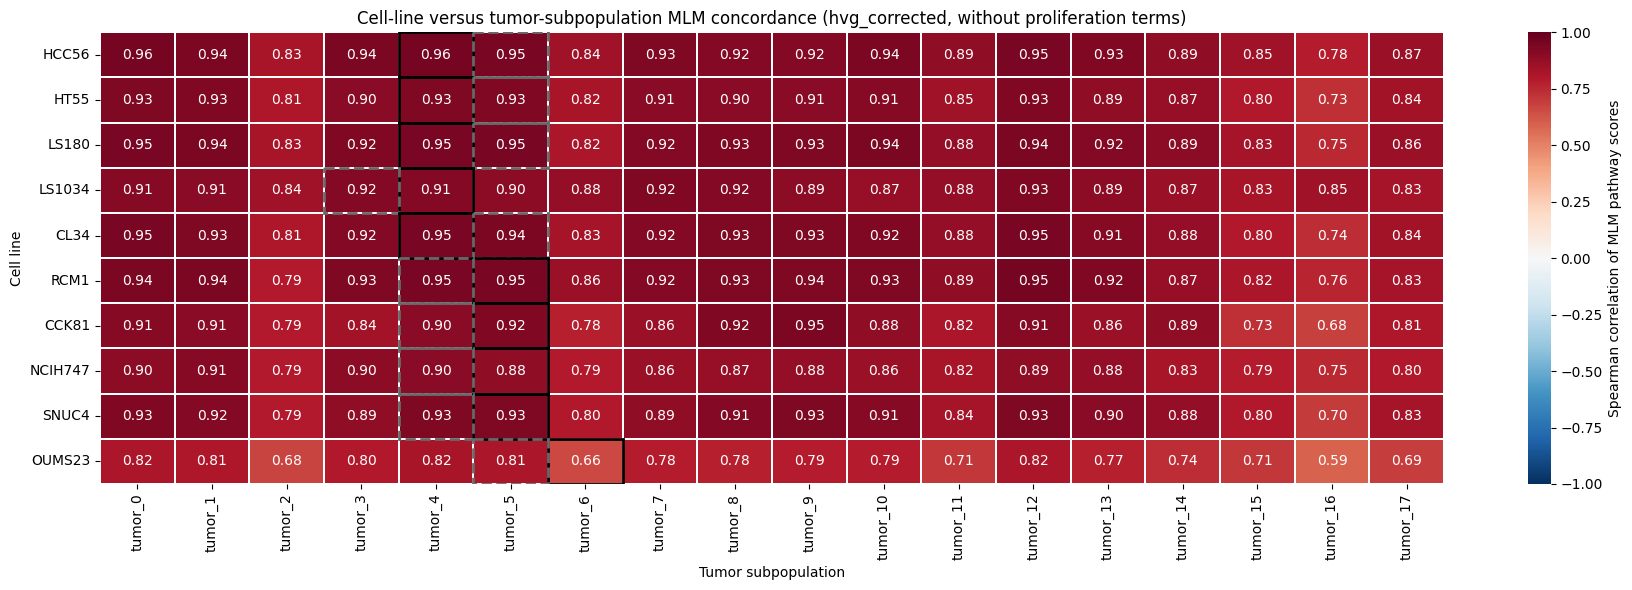

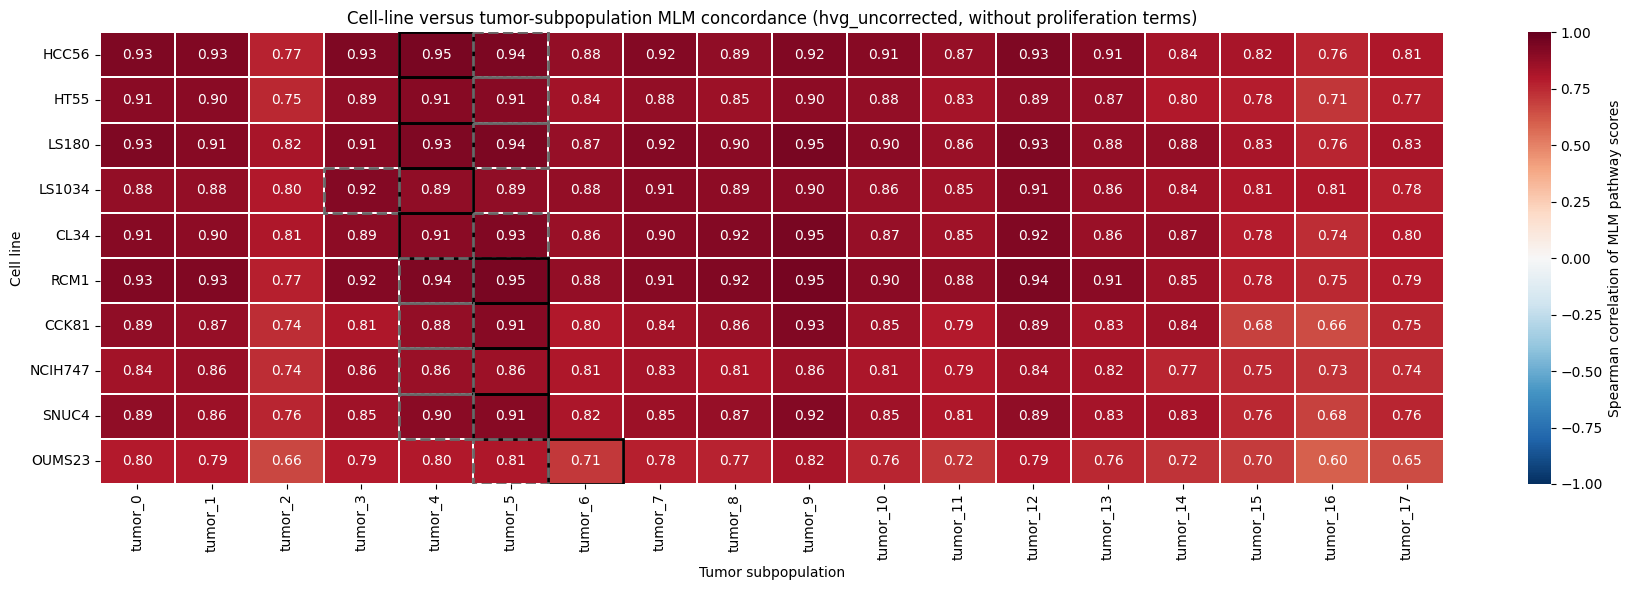

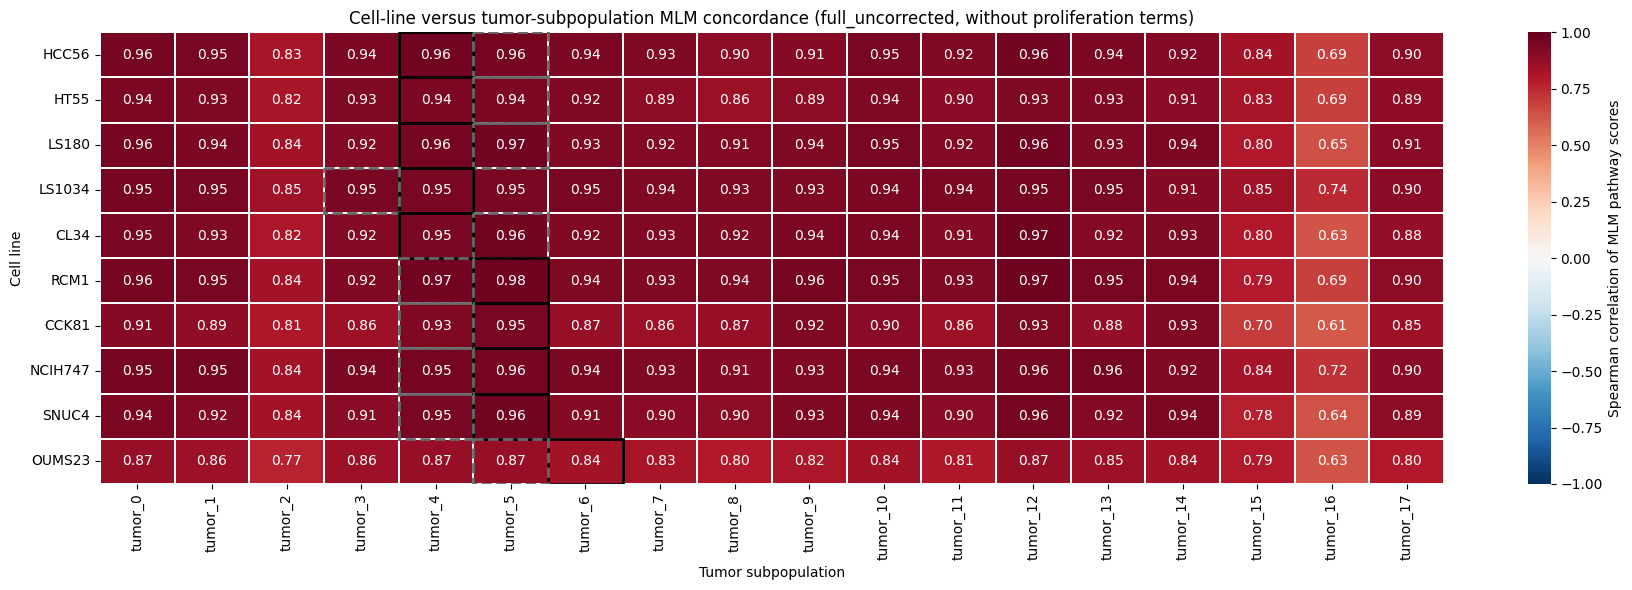

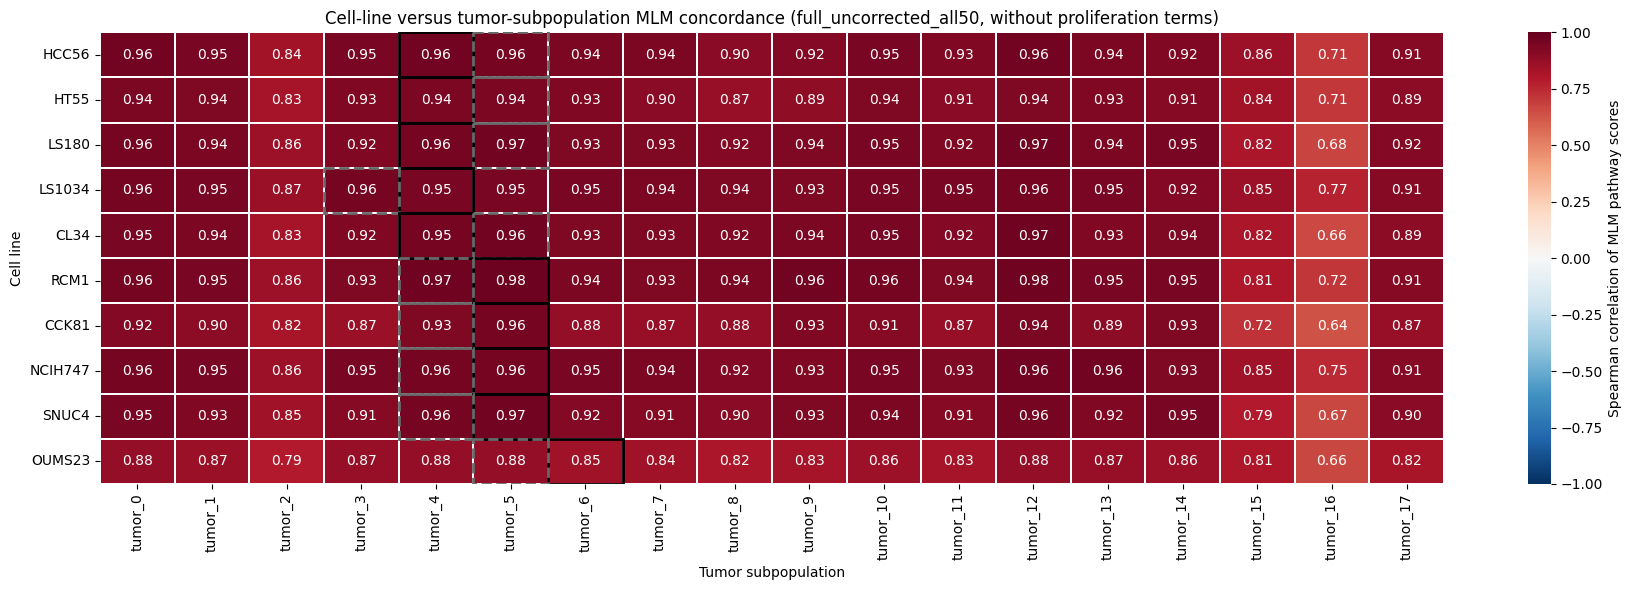

In [6]:
def add_match_boxes(ax, matrix):
    for y, cell_line in enumerate(matrix.index):
        for group, color, linestyle in [
            (line_matches.loc[cell_line, "primary_match"], "black", "-"),
            (line_matches.loc[cell_line, "second_match"], "dimgray", "--"),
        ]:
            if group in matrix.columns:
                x = matrix.columns.get_loc(group)
                ax.add_patch(
                    Rectangle((x, y), 1, 1, fill=False, edgecolor=color,
                              linewidth=2.0, linestyle=linestyle)
                )


for label in REPRESENTATION_LABELS + ["full_uncorrected_all50"]:
    matrix = (
        concordance_full_all50_noprolif
        if label == "full_uncorrected_all50"
        else concordance_noprolif[label]
    )
    fig, ax = plt.subplots(figsize=(18, 6))
    sns.heatmap(
        matrix,
        ax=ax,
        cmap="RdBu_r",
        center=0,
        vmin=-1,
        vmax=1,
        annot=True,
        fmt=".2f",
        linewidths=0.3,
        cbar_kws={"label": "Spearman correlation of MLM pathway scores"},
    )
    add_match_boxes(ax, matrix)
    ax.set_title(
        f"Cell-line versus tumor-subpopulation MLM concordance "
        f"({label}, without proliferation terms)"
    )
    ax.set_xlabel("Tumor subpopulation")
    ax.set_ylabel("Cell line")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
    plt.tight_layout()
    fig.savefig(FIG_DIR / f"mlm_concordance_{label}_noprolif.png", dpi=300, bbox_inches="tight")
    plt.show()

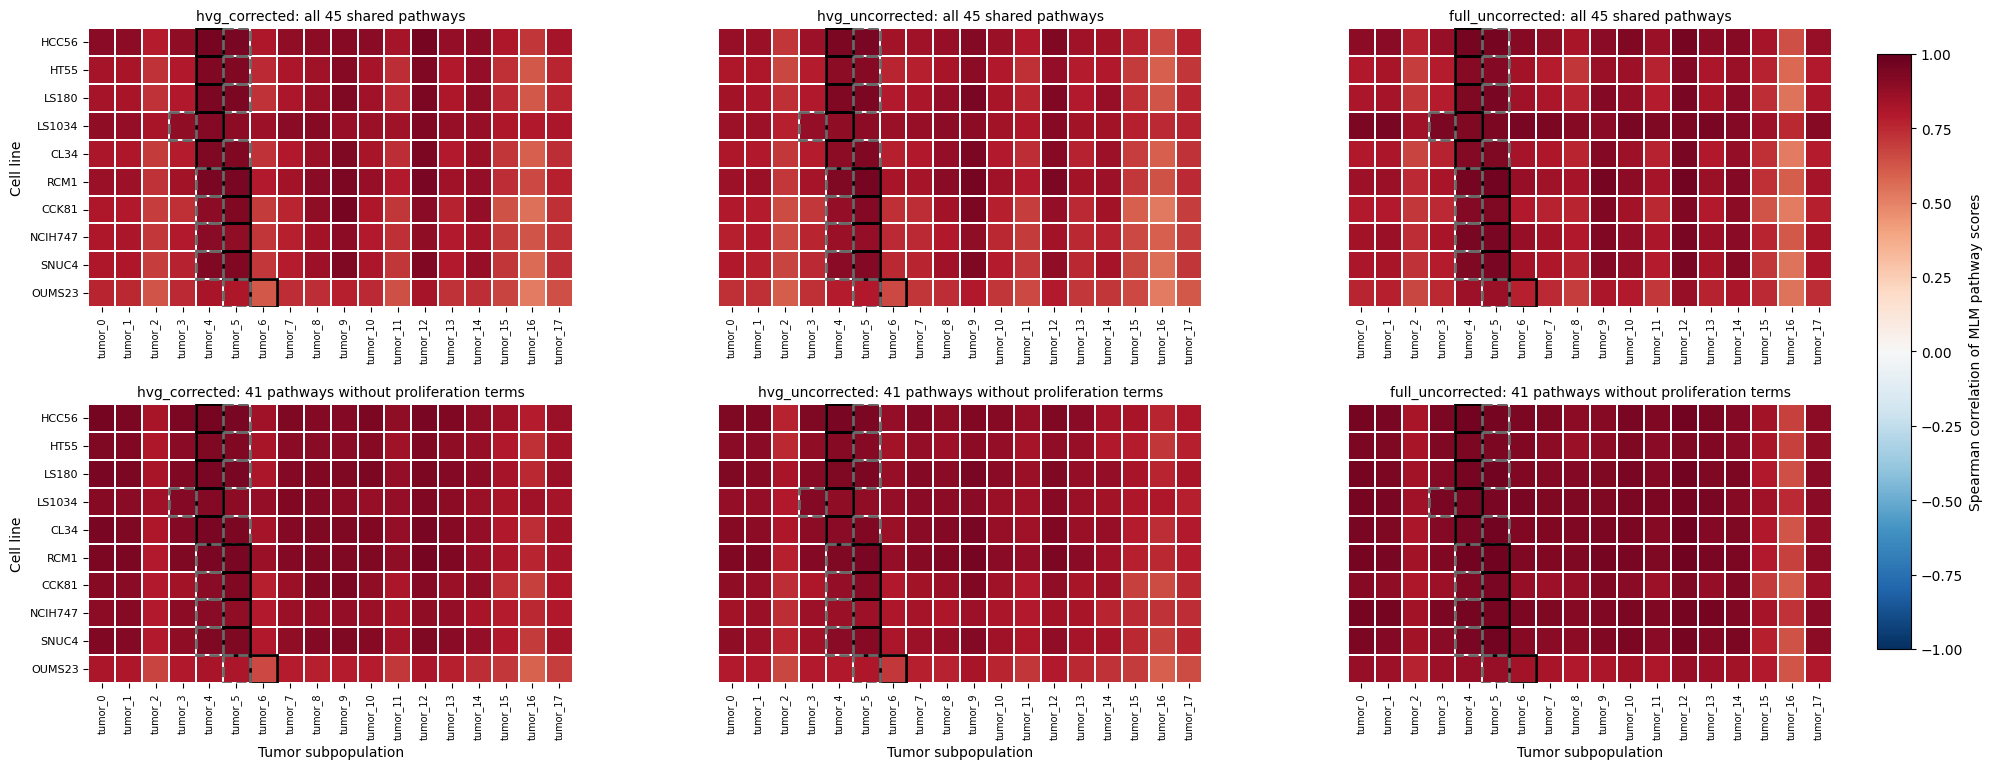

In [7]:
fig, axes = plt.subplots(
    2, len(REPRESENTATION_LABELS), figsize=(7.5 * len(REPRESENTATION_LABELS), 8.5)
)
for col, label in enumerate(REPRESENTATION_LABELS):
    panels = [
        (all_pathway[label], f"{label}: all {len(SHARED_PATHWAYS)} shared pathways"),
        (concordance_noprolif[label], f"{label}: {len(SHARED_NOPROLIF)} pathways without proliferation terms"),
    ]
    for row, (matrix, title) in enumerate(panels):
        ax = axes[row, col]
        sns.heatmap(
            matrix,
            ax=ax,
            cmap="RdBu_r",
            center=0,
            vmin=-1,
            vmax=1,
            linewidths=0.3,
            cbar=False,
            xticklabels=True,
            yticklabels=(col == 0),
        )
        add_match_boxes(ax, matrix)
        ax.set_title(title, fontsize=10)
        ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=7)
        ax.set_yticklabels(ax.get_yticklabels(), fontsize=8)
        ax.set_xlabel("Tumor subpopulation" if row == 1 else "")
        ax.set_ylabel("Cell line" if col == 0 else "")
fig.subplots_adjust(right=0.9, wspace=0.3, hspace=0.35)
colorbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
fig.colorbar(axes[0, 0].collections[0], cax=colorbar_ax).set_label(
    "Spearman correlation of MLM pathway scores"
)
fig.savefig(FIG_DIR / "mlm_concordance_noprolif_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

# Summary

In [8]:
summary_rows = []
for label in REPRESENTATION_LABELS:
    matrix = concordance_noprolif[label]
    values = matrix.to_numpy(dtype=float).ravel()
    old_values = all_pathway[label].to_numpy(dtype=float).ravel()

    deltas_new = np.array([
        matrix.loc[cell_line, line_matches.loc[cell_line, "primary_match"]]
        - matrix.loc[cell_line, line_matches.loc[cell_line, "second_match"]]
        for cell_line in LINE_ORDER
    ])
    deltas_old = np.array([
        all_pathway[label].loc[cell_line, line_matches.loc[cell_line, "primary_match"]]
        - all_pathway[label].loc[cell_line, line_matches.loc[cell_line, "second_match"]]
        for cell_line in LINE_ORDER
    ])
    top1_new = sum(
        matrix.loc[cell_line].idxmax() == line_matches.loc[cell_line, "primary_match"]
        for cell_line in LINE_ORDER
    )
    top1_old = sum(
        all_pathway[label].loc[cell_line].idxmax() == line_matches.loc[cell_line, "primary_match"]
        for cell_line in LINE_ORDER
    )

    summary_rows.append({
        "representation": label,
        "n_genes": n_genes_by_representation[label],
        "n_pathways": len(SHARED_NOPROLIF),
        "min_rho": float(values.min()),
        "median_rho": float(np.median(values)),
        "max_rho": float(values.max()),
        "spearman_vs_all_pathways": pd.Series(old_values).corr(pd.Series(values), method="spearman"),
        "n_primary_gt_runner_up": int((deltas_new > 0).sum()),
        "n_primary_gt_runner_up_all_pathways": int((deltas_old > 0).sum()),
        "median_primary_minus_runner_up": float(np.median(deltas_new)),
        "median_primary_minus_runner_up_all_pathways": float(np.median(deltas_old)),
        "n_primary_top1": int(top1_new),
        "n_primary_top1_all_pathways": int(top1_old),
    })

summary = pd.DataFrame(summary_rows).set_index("representation")
summary.to_csv(SENS_DIR / "summary_no_proliferation.csv")
display(summary.round(3))

,n_genes,n_pathways,min_rho,median_rho,max_rho,spearman_vs_all_pathways,n_primary_gt_runner_up,n_primary_gt_runner_up_all_pathways,median_primary_minus_runner_up,median_primary_minus_runner_up_all_pathways,n_primary_top1,n_primary_top1_all_pathways
representation,,,,,,,,,,,,
hvg_corrected,1135,41,0.586,0.887,0.959,0.852,6,7,0.002,0.004,4,3
hvg_uncorrected,1135,41,0.598,0.859,0.955,0.900,5,5,0.001,0.004,2,0
full_uncorrected,4237,41,0.610,0.924,0.976,0.851,6,3,0.001,-0.004,4,3


In [9]:
for name, matrices in [
    (f"all {len(SHARED_PATHWAYS)} shared pathways", all_pathway),
    (f"{len(SHARED_NOPROLIF)} pathways without proliferation terms", concordance_noprolif),
]:
    flattened = pd.DataFrame({
        label: matrices[label].to_numpy(dtype=float).ravel()
        for label in REPRESENTATION_LABELS
    })
    print(f"Cross-representation Spearman correlation of the concordance matrices, {name}:")
    display(flattened.corr(method="spearman").round(3))

flattened_full = pd.DataFrame({
    "shared_41_no_prolif": concordance_noprolif["full_uncorrected"].to_numpy(dtype=float).ravel(),
    "full_45_no_prolif": concordance_full_all50_noprolif.to_numpy(dtype=float).ravel(),
})
print("full_uncorrected: all-50-minus-5 versus shared-41, Spearman:",
      round(flattened_full.corr(method="spearman").iloc[0, 1], 3))

Cross-representation Spearman correlation of the concordance matrices, all 45 shared pathways:


,hvg_corrected,hvg_uncorrected,full_uncorrected
hvg_corrected,1.000,0.966,0.856
hvg_uncorrected,0.966,1.000,0.843
full_uncorrected,0.856,0.843,1.000


Cross-representation Spearman correlation of the concordance matrices, 41 pathways without proliferation terms:


,hvg_corrected,hvg_uncorrected,full_uncorrected
hvg_corrected,1.000,0.948,0.815
hvg_uncorrected,0.948,1.000,0.810
full_uncorrected,0.815,0.810,1.000


full_uncorrected: all-50-minus-5 versus shared-41, Spearman: 0.997


In [10]:
per_line_rows = []
for cell_line in LINE_ORDER:
    primary = str(line_matches.loc[cell_line, "primary_match"])
    runner_up = str(line_matches.loc[cell_line, "second_match"])
    row = {"cell_line": cell_line, "primary_match": primary, "runner_up": runner_up}
    for label in REPRESENTATION_LABELS:
        matrix = concordance_noprolif[label]
        row[f"{label}_primary_rho"] = float(matrix.loc[cell_line, primary])
        row[f"{label}_primary_minus_runner_up"] = float(
            matrix.loc[cell_line, primary] - matrix.loc[cell_line, runner_up]
        )
    per_line_rows.append(row)

per_line = pd.DataFrame(per_line_rows).set_index("cell_line")
per_line.to_csv(SENS_DIR / "concordance_metrics_noprolif.csv")
display(per_line.round(3))

,primary_match,runner_up,hvg_corrected_primary_rho,hvg_corrected_primary_minus_runner_up,hvg_uncorrected_primary_rho,hvg_uncorrected_primary_minus_runner_up,full_uncorrected_primary_rho,full_uncorrected_primary_minus_runner_up
cell_line,,,,,,,,
HCC56,tumor_4,tumor_5,0.959,0.012,0.947,0.005,0.961,0.004
HT55,tumor_4,tumor_5,0.934,0.008,0.911,0.004,0.942,0.002
LS180,tumor_4,tumor_5,0.949,0.002,0.931,-0.008,0.957,-0.009
LS1034,tumor_4,tumor_3,0.915,-0.004,0.885,-0.032,0.948,-0.005
CL34,tumor_4,tumor_5,0.947,0.004,0.906,-0.019,0.952,-0.010
RCM1,tumor_5,tumor_4,0.947,-0.002,0.946,0.011,0.976,0.009
CCK81,tumor_5,tumor_4,0.924,0.023,0.909,0.028,0.950,0.024
NCIH747,tumor_5,tumor_4,0.884,-0.020,0.858,-0.002,0.956,0.001
SNUC4,tumor_5,tumor_4,0.934,0.001,0.913,0.011,0.961,0.009
